# PROJETO DE COLETA DE DADOS
## Clima atual das capitais brasileiras (API Open-Meteo)

**Autor:** Rendell Leão da Costa Arruda  
**Data:** 08/11/26  
**Disciplina:** Introdução à Ciência de Dados    
**Método:** API (requests + pandas + matplotlib)

---
## Objetivo: 
Coletar dados meteorológicos atuais de capitais brasileiras pela API gratuita Open-Meteo, limpar e organizar os dados em um dataset CSV, explorá-los e documentar o processo.

## Fonte dos dados: 

Fonte: Open-Meteo	
URL	: https://open-meteo.com	
Método: API REST (requisições HTTP com Python)	
Dados Coletados: Temperatura atual, umidade relativa do ar e velocidade do vento de 12 capitais brasileiras.

**Como este notebook está organizado:** 1) Configuração → 2) Coleta → 3) Limpeza → 4) Processamento → 5) Análise exploratória → 6) Gráficos → 7) Documentação (gerada automaticamente a partir dos dados) → 8) Checklist.

## 1 Configuração

In [2]:
import os
import time
from datetime import datetime

import requests                       # faz as requisições HTTP à API
import pandas as pd                   # tabelas (DataFrame)
import numpy as np                    # usado na classificação por faixas
import matplotlib.pyplot as plt       # gráficos
from IPython.display import Markdown, display

URL_API = "https://api.open-meteo.com/v1/forecast"                    # endpoint da Open-Meteo (gratuito, sem chave)
VARIAVEIS = "temperature_2m,relative_humidity_2m,wind_speed_10m"     # o que pedimos para a API

# Capitais: nome -> (latitude, longitude)
CIDADES = {
    "São Paulo": (-23.55, -46.63),
    "Rio de Janeiro": (-22.91, -43.17),
    "Belo Horizonte": (-19.92, -43.94),
    "Brasília": (-15.79, -47.88),
    "Curitiba": (-25.43, -49.27),
    "Porto Alegre": (-30.03, -51.23),
    "Salvador": (-12.97, -38.50),
    "Recife": (-8.05, -34.88),
    "Fortaleza": (-3.73, -38.52),
    "Manaus": (-3.12, -60.02),
    "Belém": (-1.46, -48.50),
    "Goiânia": (-16.68, -49.25),
}
print(f"{len(CIDADES)} cidades configuradas para a coleta.")

12 cidades configuradas para a coleta.


## 2. Coleta (API)
A função consulta **uma cidade por vez**. Se a requisição falhar (erro de rede, status 404/429, JSON inválido), ela avisa e devolve `None`, assim o código **não quebra** e o progresso das outras cidades é mantido (`try/except`).

In [3]:
def coletar_clima(cidade, latitude, longitude):
    """Consulta a API para UMA cidade e devolve um dicionário (ou None se falhar)."""
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "current": VARIAVEIS,
        "timezone": "America/Sao_Paulo",   # mesmo fuso para todas (horário de Brasília)
    }
    try:
        resposta = requests.get(URL_API, params=params, timeout=15)
        resposta.raise_for_status()            # levanta erro se o status não for 200
        atual = resposta.json()["current"]     # bloco com as medições atuais
    except (requests.RequestException, KeyError, ValueError) as erro:
        print(f"Falha em {cidade}: {erro}")
        return None

    return {
        "cidade": cidade,
        "latitude": latitude,
        "longitude": longitude,
        "data_hora": atual.get("time"),                    # .get() evita KeyError se faltar a chave
        "temperatura": atual.get("temperature_2m"),
        "umidade": atual.get("relative_humidity_2m"),
        "vento": atual.get("wind_speed_10m"),
        "coletado_em": datetime.now().isoformat(timespec="seconds"),
    }


dados_brutos = []
for cidade, (lat, lon) in CIDADES.items():
    registro = coletar_clima(cidade, lat, lon)
    if registro is not None:
        dados_brutos.append(registro)
    time.sleep(0.5)        # pausa entre requisições (boa prática: evita rate limit / erro 429)

df_bruto = pd.DataFrame(dados_brutos)
df_bruto.to_csv("clima_bruto.csv", index=False, encoding="utf-8")   # preserva os dados originais

print("Formato dos dados brutos (linhas, colunas):", df_bruto.shape)
if len(df_bruto) < 10:
    print("Atenção: menos de 10 registros coletados. Rode a célula novamente.")
df_bruto.head()

Formato dos dados brutos (linhas, colunas): (12, 8)


,cidade,latitude,longitude,data_hora,temperatura,umidade,vento,coletado_em
0,São Paulo,-23.55,-46.63,2026-11-09T06:15,13.6,92,10.8,2026-11-09T06:18:47
1,Rio de Janeiro,-22.91,-43.17,2026-11-09T06:15,19.3,87,12.7,2026-11-09T06:18:48
2,Belo Horizonte,-19.92,-43.94,2026-11-09T06:15,16.1,87,9.7,2026-11-09T06:18:49
3,Brasília,-15.79,-47.88,2026-11-09T06:15,20.6,86,11.0,2026-11-09T06:18:50
4,Curitiba,-25.43,-49.27,2026-11-09T06:15,10.6,92,8.6,2026-11-09T06:18:51


## 3. Limpeza
Etapas: verificar ausentes → converter tipos → tratar ausentes → remover duplicatas → renomear colunas → filtrar valores impossíveis.
Trabalhamos em uma **cópia** (`df`) e o `df_bruto` fica intacto.

In [4]:
df = df_bruto.copy()
n_inicial = len(df)

# 1. Valores ausentes por coluna
print("Ausentes antes da limpeza:")
print(df.isnull().sum())

# 2. Conversão de tipos
for coluna in ["temperatura", "umidade", "vento"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")   # texto inválido vira NaN
df["data_hora"] = pd.to_datetime(df["data_hora"])
df["coletado_em"] = pd.to_datetime(df["coletado_em"])

# 3. Tratar ausentes: sem as medições principais o registro não serve, então removemos a linha
df = df.dropna(subset=["temperatura", "umidade", "vento"])

# 4. Duplicatas (mesma cidade no mesmo horário)
df = df.drop_duplicates(subset=["cidade", "data_hora"])

# 5. Renomear colunas (nomes com unidade, mais claros)
df = df.rename(columns={
    "temperatura": "temperatura_c",
    "umidade": "umidade_pct",
    "vento": "vento_kmh",
})

# 6. Filtro de plausibilidade (valores fisicamente impossíveis são descartados)
df = df[
    df["temperatura_c"].between(-60, 60)
    & df["umidade_pct"].between(0, 100)
    & (df["vento_kmh"] >= 0)
]

n_final = len(df)
print(f"\nRegistros: {n_inicial} antes -> {n_final} depois da limpeza")
print("\nTipos de dados:")
print(df.dtypes)

Ausentes antes da limpeza:
cidade         0
latitude       0
longitude      0
data_hora      0
temperatura    0
umidade        0
vento          0
coletado_em    0
dtype: int64

Registros: 12 antes -> 12 depois da limpeza

Tipos de dados:
cidade                      str
latitude                float64
longitude               float64
data_hora        datetime64[us]
temperatura_c           float64
umidade_pct               int64
vento_kmh               float64
coletado_em      datetime64[us]
dtype: object


## 4. Processamento
Criamos duas colunas novas: a **região** de cada capital e a **faixa de temperatura**. Depois salvamos o dataset final em CSV.

In [5]:
REGIOES = {
    "São Paulo": "Sudeste", "Rio de Janeiro": "Sudeste", "Belo Horizonte": "Sudeste",
    "Brasília": "Centro-Oeste", "Goiânia": "Centro-Oeste",
    "Curitiba": "Sul", "Porto Alegre": "Sul",
    "Salvador": "Nordeste", "Recife": "Nordeste", "Fortaleza": "Nordeste",
    "Manaus": "Norte", "Belém": "Norte",
}

df["regiao"] = df["cidade"].map(REGIOES)

# Faixas: até 18 °C = Fria | 18-25 = Amena | 25-30 = Quente | acima de 30 = Muito quente
df["faixa_temperatura"] = pd.cut(
    df["temperatura_c"],
    bins=[-np.inf, 18, 25, 30, np.inf],
    labels=["Fria", "Amena", "Quente", "Muito quente"],
)

# Ordem final das colunas
df = df[["cidade", "regiao", "latitude", "longitude", "data_hora",
         "temperatura_c", "umidade_pct", "vento_kmh", "faixa_temperatura", "coletado_em"]]
df = df.reset_index(drop=True)

df.to_csv("dataset_clima_brasil.csv", index=False, encoding="utf-8")
print("Dataset final salvo em dataset_clima_brasil.csv")
df.head()

Dataset final salvo em dataset_clima_brasil.csv


,cidade,regiao,latitude,longitude,data_hora,temperatura_c,umidade_pct,vento_kmh,faixa_temperatura,coletado_em
0,São Paulo,Sudeste,-23.55,-46.63,2026-11-09 06:15:00,13.6,92,10.8,Fria,2026-11-09 06:18:47
1,Rio de Janeiro,Sudeste,-22.91,-43.17,2026-11-09 06:15:00,19.3,87,12.7,Amena,2026-11-09 06:18:48
2,Belo Horizonte,Sudeste,-19.92,-43.94,2026-11-09 06:15:00,16.1,87,9.7,Fria,2026-11-09 06:18:49
3,Brasília,Centro-Oeste,-15.79,-47.88,2026-11-09 06:15:00,20.6,86,11.0,Amena,2026-11-09 06:18:50
4,Curitiba,Sul,-25.43,-49.27,2026-11-09 06:15:00,10.6,92,8.6,Fria,2026-11-09 06:18:51


## 5. Análise exploratória

In [6]:
print("Formato (linhas, colunas):", df.shape)
print("\nPrimeiras linhas:")
print(df.head())
print("\nTipos:")
print(df.dtypes)
print("\nEstatísticas descritivas:")
print(df.describe())
print("\nAusentes por coluna:")
print(df.isnull().sum())
print("\nColunas:", df.columns.tolist())

print("\nMédias por região:")
print(df.groupby("regiao")[["temperatura_c", "umidade_pct", "vento_kmh"]].mean().round(2))

Formato (linhas, colunas): (12, 10)

Primeiras linhas:
           cidade        regiao  latitude  longitude           data_hora  \
0       São Paulo       Sudeste    -23.55     -46.63 2026-11-09 06:15:00   
1  Rio de Janeiro       Sudeste    -22.91     -43.17 2026-11-09 06:15:00   
2  Belo Horizonte       Sudeste    -19.92     -43.94 2026-11-09 06:15:00   
3        Brasília  Centro-Oeste    -15.79     -47.88 2026-11-09 06:15:00   
4        Curitiba           Sul    -25.43     -49.27 2026-11-09 06:15:00   

   temperatura_c  umidade_pct  vento_kmh faixa_temperatura         coletado_em  
0           13.6           92       10.8              Fria 2026-11-09 06:18:47  
1           19.3           87       12.7             Amena 2026-11-09 06:18:48  
2           16.1           87        9.7              Fria 2026-11-09 06:18:49  
3           20.6           86       11.0             Amena 2026-11-09 06:18:50  
4           10.6           92        8.6              Fria 2026-11-09 06:18:51  

T

## 6. Visualizações
**Gráfico 1 (barras):** compara variáveis categóricas (cidades) com uma variável numérica.  
**Gráfico 2 (dispersão):** mostra a relação entre duas variáveis numéricas contínuas (temperatura e umidade).

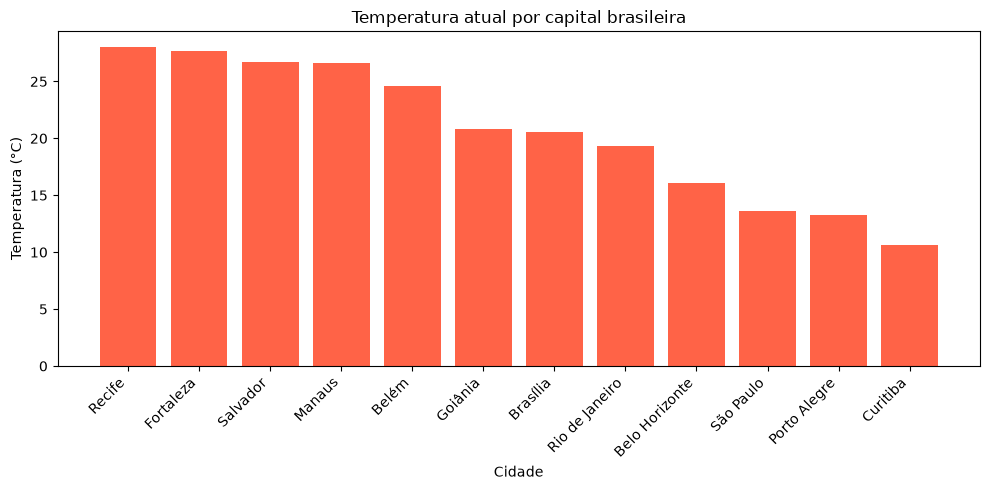

In [7]:
# Gráfico 1: temperatura por cidade (barras)
ordenado = df.sort_values("temperatura_c", ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(ordenado["cidade"], ordenado["temperatura_c"], color="tomato")
plt.title("Temperatura atual por capital brasileira")
plt.xlabel("Cidade")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("grafico_temperatura.png", dpi=150)
plt.show()

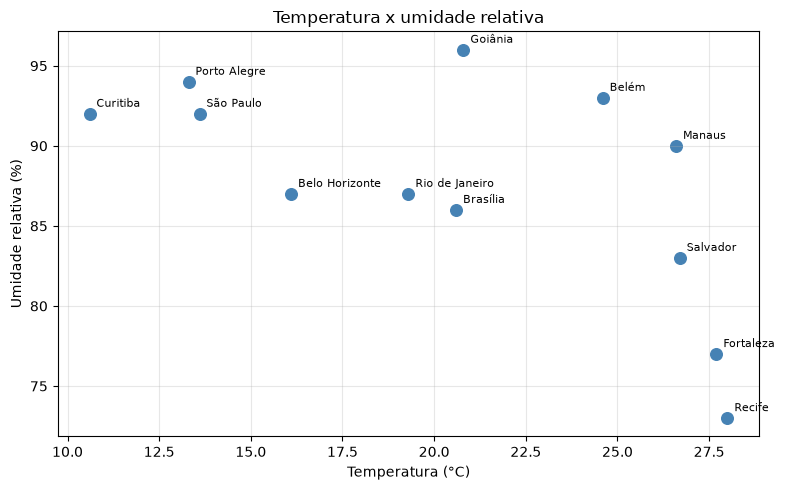

In [8]:
# Gráfico 2: temperatura x umidade (dispersão)
plt.figure(figsize=(8, 5))
plt.scatter(df["temperatura_c"], df["umidade_pct"], color="steelblue", s=70)
for _, linha in df.iterrows():
    plt.annotate(linha["cidade"], (linha["temperatura_c"], linha["umidade_pct"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.title("Temperatura x umidade relativa")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Umidade relativa (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("grafico_temp_umidade.png", dpi=150)
plt.show()

## 7. Documentação
A célula abaixo **gera o arquivo `documentacao.md`** (seguindo o template da disciplina) usando os valores reais do dataset: datas, número de registros, tamanho do arquivo, estatísticas e insights são calculados pelo código, não digitados à mão.

In [9]:
# ---- Valores calculados a partir dos dados ----
data_coleta = df["coletado_em"].min().strftime("%d/%m/%Y")
periodo_ini = df["data_hora"].min().strftime("%d/%m/%Y %H:%M")
periodo_fim = df["data_hora"].max().strftime("%d/%m/%Y %H:%M")
tamanho_kb = os.path.getsize("dataset_clima_brasil.csv") / 1024

mais_quente = df.loc[df["temperatura_c"].idxmax()]
mais_fria = df.loc[df["temperatura_c"].idxmin()]
mais_ventosa = df.loc[df["vento_kmh"].idxmax()]
media_regiao = df.groupby("regiao")["temperatura_c"].mean().sort_values(ascending=False)
corr = df["temperatura_c"].corr(df["umidade_pct"])

if corr <= -0.3:
    leitura_corr = "negativa: nas cidades mais quentes a umidade tende a ser menor neste instante"
elif corr >= 0.3:
    leitura_corr = "positiva: nas cidades mais quentes a umidade tende a ser maior neste instante"
else:
    leitura_corr = "fraca: não há relação clara entre temperatura e umidade nesta amostra"

descricoes = {
    "cidade": "Nome da capital",
    "regiao": "Região do Brasil",
    "latitude": "Latitude usada na consulta",
    "longitude": "Longitude usada na consulta",
    "data_hora": "Horário da medição (Brasília)",
    "temperatura_c": "Temperatura do ar a 2 m (°C)",
    "umidade_pct": "Umidade relativa a 2 m (%)",
    "vento_kmh": "Velocidade do vento a 10 m (km/h)",
    "faixa_temperatura": "Faixa: Fria (até 18), Amena, Quente (25-30), Muito quente (acima de 30)",
    "coletado_em": "Momento em que o script coletou o dado",
}
linhas_colunas = "\n".join(
    f"| {col} | {tipo} | {descricoes.get(col, '')} |" for col, tipo in df.dtypes.astype(str).items()
)
estatisticas = df[["temperatura_c", "umidade_pct", "vento_kmh"]].describe().round(2).to_string()
tabela_regiao = media_regiao.round(1).to_string()

documentacao = f"""# PROJETO DE COLETA DE DADOS
## Clima atual das capitais brasileiras (Open-Meteo)

**Autor:** Rendell Leão da Costa Arruda
**Data da coleta:** {data_coleta}
**Disciplina:** Introdução à Ciência de Dados

---

## 1. OBJETIVO
Coletar dados meteorológicos atuais (temperatura, umidade e vento) de {len(CIDADES)} capitais brasileiras por meio de uma API pública, organizá-los em um dataset limpo e explorar as diferenças entre cidades e regiões do país.

## 2. FONTES DE DADOS
| Fonte | URL | Método | Dados Coletados |
|-------|-----|--------|-----------------|
| Open-Meteo | https://open-meteo.com | API | Temperatura, umidade relativa e velocidade do vento atuais |

## 3. METODOLOGIA
### 3.1 Coleta
Uma requisição GET por cidade ao endpoint `{URL_API}`, com latitude, longitude e as variáveis `{VARIAVEIS}`, usando a biblioteca `requests`. O código usa `try/except`, `raise_for_status()` e uma pausa de 0,5 s entre as requisições. Os dados originais foram salvos em `clima_bruto.csv` antes de qualquer limpeza.

### 3.2 Limpeza
Verificação de valores ausentes, conversão de tipos (`to_numeric` e `to_datetime`), remoção de linhas sem medições, remoção de duplicatas (mesma cidade e horário), renomeação das colunas e filtro de plausibilidade (temperatura entre -60 e 60 °C, umidade entre 0 e 100 %, vento maior ou igual a zero). Registros: {n_inicial} coletados, {n_final} após a limpeza.

### 3.3 Processamento
Criação das colunas `regiao` (mapeamento manual de cada capital) e `faixa_temperatura` (classificação com `pd.cut`).

## 4. DATASET FINAL
- **Total de registros:** {df.shape[0]}
- **Total de colunas:** {df.shape[1]}
- **Período:** {periodo_ini} a {periodo_fim}
- **Tamanho do arquivo:** {tamanho_kb:.1f} KB (`dataset_clima_brasil.csv`)

### Colunas:
| Coluna | Tipo | Descrição |
|--------|------|-----------|
{linhas_colunas}

## 5. ANÁLISE EXPLORATÓRIA
### 5.1 Estatísticas Descritivas
```
{estatisticas}
```

Temperatura média por região (°C):
```
{tabela_regiao}
```

### 5.2 Visualizações
- `grafico_temperatura.png`: barras com a temperatura de cada capital.
- `grafico_temp_umidade.png`: dispersão entre temperatura e umidade.

## 6. INSIGHTS
1. A capital mais quente da coleta foi {mais_quente['cidade']} ({mais_quente['temperatura_c']:.1f} °C) e a mais fria foi {mais_fria['cidade']} ({mais_fria['temperatura_c']:.1f} °C), uma amplitude de {mais_quente['temperatura_c'] - mais_fria['temperatura_c']:.1f} °C.
2. A região com maior temperatura média foi {media_regiao.index[0]} ({media_regiao.iloc[0]:.1f} °C) e a de menor foi {media_regiao.index[-1]} ({media_regiao.iloc[-1]:.1f} °C).
3. A correlação entre temperatura e umidade foi de {corr:.2f}, {leitura_corr}. O vento mais forte foi em {mais_ventosa['cidade']} ({mais_ventosa['vento_kmh']:.1f} km/h).

## 7. LIMITAÇÕES
- Os dados são uma fotografia de um único instante, então não mostram variação ao longo do dia ou da semana.
- Foram usadas {len(CIDADES)} capitais, uma amostra que não representa todo o país.
- Os valores são estimativas de modelos meteorológicos agregados pela Open-Meteo, e não medições de uma estação física em cada cidade.

## 8. PRÓXIMOS PASSOS
- Repetir a coleta em intervalos regulares (por exemplo, com `schedule`) para formar uma série temporal.
- Incluir previsão e histórico de dias anteriores e mais cidades.
- Publicar o projeto no GitHub com README.

## 9. CÓDIGO
Notebook `projeto_coleta_clima.ipynb`. Repositório no GitHub: https://github.com/rendell-arruda/projeto_coleta_clima

## 10. REFERÊNCIAS
- Open-Meteo, documentação da API: https://open-meteo.com/en/docs
- Documentação do pandas: https://pandas.pydata.org/docs/
- Slides da Aula 4.2 (Processamento e Coleta de Dados), Prof. Danilo César Pereira
"""

with open("documentacao.md", "w", encoding="utf-8") as arquivo:
    arquivo.write(documentacao)

display(Markdown(documentacao))

# PROJETO DE COLETA DE DADOS
## Clima atual das capitais brasileiras (Open-Meteo)

**Autor:** Rendell Leão da Costa Arruda
**Data da coleta:** 09/11/2026
**Disciplina:** Introdução à Ciência de Dados

---

## 1. OBJETIVO
Coletar dados meteorológicos atuais (temperatura, umidade e vento) de 12 capitais brasileiras por meio de uma API pública, organizá-los em um dataset limpo e explorar as diferenças entre cidades e regiões do país.

## 2. FONTES DE DADOS
| Fonte | URL | Método | Dados Coletados |
|-------|-----|--------|-----------------|
| Open-Meteo | https://open-meteo.com | API | Temperatura, umidade relativa e velocidade do vento atuais |

## 3. METODOLOGIA
### 3.1 Coleta
Uma requisição GET por cidade ao endpoint `https://api.open-meteo.com/v1/forecast`, com latitude, longitude e as variáveis `temperature_2m,relative_humidity_2m,wind_speed_10m`, usando a biblioteca `requests`. O código usa `try/except`, `raise_for_status()` e uma pausa de 0,5 s entre as requisições. Os dados originais foram salvos em `clima_bruto.csv` antes de qualquer limpeza.

### 3.2 Limpeza
Verificação de valores ausentes, conversão de tipos (`to_numeric` e `to_datetime`), remoção de linhas sem medições, remoção de duplicatas (mesma cidade e horário), renomeação das colunas e filtro de plausibilidade (temperatura entre -60 e 60 °C, umidade entre 0 e 100 %, vento maior ou igual a zero). Registros: 12 coletados, 12 após a limpeza.

### 3.3 Processamento
Criação das colunas `regiao` (mapeamento manual de cada capital) e `faixa_temperatura` (classificação com `pd.cut`).

## 4. DATASET FINAL
- **Total de registros:** 12
- **Total de colunas:** 10
- **Período:** 09/11/2026 06:15 a 09/11/2026 06:15
- **Tamanho do arquivo:** 1.2 KB (`dataset_clima_brasil.csv`)

### Colunas:
| Coluna | Tipo | Descrição |
|--------|------|-----------|
| cidade | str | Nome da capital |
| regiao | str | Região do Brasil |
| latitude | float64 | Latitude usada na consulta |
| longitude | float64 | Longitude usada na consulta |
| data_hora | datetime64[us] | Horário da medição (Brasília) |
| temperatura_c | float64 | Temperatura do ar a 2 m (°C) |
| umidade_pct | int64 | Umidade relativa a 2 m (%) |
| vento_kmh | float64 | Velocidade do vento a 10 m (km/h) |
| faixa_temperatura | category | Faixa: Fria (até 18), Amena, Quente (25-30), Muito quente (acima de 30) |
| coletado_em | datetime64[us] | Momento em que o script coletou o dado |

## 5. ANÁLISE EXPLORATÓRIA
### 5.1 Estatísticas Descritivas
```
       temperatura_c  umidade_pct  vento_kmh
count          12.00        12.00      12.00
mean           20.66        87.50       7.89
std             6.17         6.97       3.61
min            10.60        73.00       1.70
25%            15.48        85.25       4.42
50%            20.70        88.50       9.15
75%            26.62        92.25      10.85
max            28.00        96.00      12.70
```

Temperatura média por região (°C):
```
regiao
Nordeste        27.5
Norte           25.6
Centro-Oeste    20.7
Sudeste         16.3
Sul             12.0
```

### 5.2 Visualizações
- `grafico_temperatura.png`: barras com a temperatura de cada capital.
- `grafico_temp_umidade.png`: dispersão entre temperatura e umidade.

## 6. INSIGHTS
1. A capital mais quente da coleta foi Recife (28.0 °C) e a mais fria foi Curitiba (10.6 °C), uma amplitude de 17.4 °C.
2. A região com maior temperatura média foi Nordeste (27.5 °C) e a de menor foi Sul (11.9 °C).
3. A correlação entre temperatura e umidade foi de -0.62, negativa: nas cidades mais quentes a umidade tende a ser menor neste instante. O vento mais forte foi em Rio de Janeiro (12.7 km/h).

## 7. LIMITAÇÕES
- Os dados são uma fotografia de um único instante, então não mostram variação ao longo do dia ou da semana.
- Foram usadas 12 capitais, uma amostra que não representa todo o país.
- Os valores são estimativas de modelos meteorológicos agregados pela Open-Meteo, e não medições de uma estação física em cada cidade.

## 8. PRÓXIMOS PASSOS
- Repetir a coleta em intervalos regulares (por exemplo, com `schedule`) para formar uma série temporal.
- Incluir previsão e histórico de dias anteriores e mais cidades.
- Publicar o projeto no GitHub com README.

## 9. CÓDIGO
Notebook `projeto_coleta_clima.ipynb`. Repositório no GitHub: https://github.com/rendell-arruda/projeto_coleta_clima

## 10. REFERÊNCIAS
- Open-Meteo, documentação da API: https://open-meteo.com/en/docs
- Documentação do pandas: https://pandas.pydata.org/docs/
- Slides da Aula 4.2 (Processamento e Coleta de Dados), Prof. Danilo César Pereira


## 8. Checklist de entrega
- [x] Tema e justificativa definidos (clima das capitais, método API)
- [x] Fonte de dados identificada (Open-Meteo)
- [x] Código implementado e executável
- [x] Mínimo de 10 registros coletados (confira em `df.shape`)
- [x] Dados limpos (tipos e ausentes)
- [x] DataFrame final criado
- [x] Análise exploratória realizada
- [x] Pelo menos um gráfico gerado (dois)
- [x] Dataset salvo em CSV (`dataset_clima_brasil.csv`)
- [x] Processo documentado (`documentacao.md`)
- [ ] Notebook salvo (use *Restart Kernel and Run All* e salve com as saídas)